# 10 · Partición temporal (split)

Este notebook reparte las fases entre desarrollo y test respetando el orden temporal, y define los folds de
validación cruzada que usan todos los baselines y modelos (notebooks 11 a 14).

1. Criterio de partición
2. Cobertura temporal de los datos
3. Diseño del reparto
4. Asignar cada orden a un bloque
5. Verificar la partición
6. Folds de validación
7. Aplicar corte de outliers en las colas
9. Tratar maquinas con poco volumen  
8. Guardado

- **Entrada:** `data/processed/df_features.parquet`
- **Salida:** `data/modeling/df_split.parquet` y `data/modeling/folds.csv`

In [257]:
import sys
from pathlib import Path

# Raíz del repositorio (la carpeta que contiene src/), para poder importar src
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

from src.rutas import FIGURES, MODELING, PROCESSED
from src.limpieza import corte_log

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

BLUE, ORANGE, GRAY = "#2E5EAA", "#D9631E", "#6B7280"  # colores de las figuras

## 1. Criterio de partición

Teniendo en cuenta la naturaleza de estos datos es necesario plantear un split temporal: se entrena con el pasado y
se evalúa con el futuro, igual que ocurriría al usar el modelo en planta. El campo `fecha_fase` permite identificar la
fecha en que se empezó la fase.

Una orden de fabricación puede tener distintas fases. Para este split es importante que las fases de una misma orden
no se separen, es decir, las fases de una misma orden no pueden aparecer en particiones distintas.

El ajuste de hiperparámetros se hace solo dentro del conjunto de desarrollo, con validación cruzada temporal
(sección 6). El test se toca una única vez, al final (notebook 15).

Dentro del test se marcan las fases de máquinas no vistas en desarrollo y su error se
reporta por separado.

In [258]:
df_features = pd.read_parquet(PROCESSED / "df_features.parquet")
df_features.head(1)

,fecha_fase,IDMOTask,smOrdenId,TipoFase,CodigoMaquina,Familia Maquinas,Línea Producto,Família Producto,Quantity,TiempoPrevisto,ratio
0,2025-10-02 03:12:05.010,ee76d685-a4cc-47d4-b418-6e33d2ae2921,OF2509545,TPP,TN09,TPU,P,PE,3.0,21.0,1.988889


## 2. Cobertura temporal de los datos

In [259]:
print(df_features.shape)
print(df_features["fecha_fase"].describe())

(14689, 11)
count                            14689
mean     2025-12-19 09:08:24.129046272
min         2025-06-02 14:01:02.623000
25%      2025-09-09 14:02:42.929999872
50%      2025-12-04 17:23:57.063000064
75%                2026-03-30 06:30:26
max         2026-07-31 17:14:04.953000
Name: fecha_fase, dtype: object


Acumulación de fases y órdenes de fabricación por trimestre:

In [260]:
resumen_trim = (
    df_features.assign(trimestre=df_features["fecha_fase"].dt.to_period("Q"))
      .groupby("trimestre")
      .agg(fases=("IDMOTask", "size"),
           ordenes=("smOrdenId", "nunique"))
)
# porcentaje acumulado de fases a medida que avanzan los trimestres
resumen_trim["fases_acum_%"] = (resumen_trim["fases"].cumsum() / len(df_features) * 100).round(1)
print(resumen_trim)

           fases  ordenes  fases_acum_%
trimestre                              
2025Q2       680      344           4.6
2025Q3      3887     1793          31.1
2025Q4      3514     1641          55.0
2026Q1      3035     1454          75.7
2026Q2      2682     1363          93.9
2026Q3       891      448         100.0


> El split se hará por meses y no por trimestres: el primer y el último trimestre del intervalo están incompletos.

Duración de las órdenes de fabricación:

In [261]:
OF_dias = (
    df_features.groupby("smOrdenId")["fecha_fase"]            # agrupar las fases por OF
      .agg(primera="min", ultima="max", n_fases="size")      # de cada grupo, la primera y la última fecha
)
OF_dias["dias"] = (OF_dias["ultima"] - OF_dias["primera"]).dt.days   # en días; menos de 24 h da 0

print(OF_dias["dias"].describe(percentiles=[.5, .75, .9, .95, .99]))

count    6501.000000
mean        6.130288
std         8.326405
min         0.000000
50%         2.000000
75%        10.000000
90%        18.000000
95%        23.000000
99%        35.000000
max        61.000000
Name: dias, dtype: float64


Las órdenes en su mayoría son cortas: auqnue la mediana muestra que estas duran 6 dias, el quartil del 50% se situa en 2 dias. Esto se refuerza con lo visto en `07_viabilidad`, hay una notable cola de ratios exageradamente elevados por imputar tiempo de más.

> El 90 % de las órdenes duran 18 días o menos, y la orden más larga registra 61 días.

> Que una orden tarde muchos días no significa que sus fases acumulen mucho tiempo: algunas órdenes, por su naturaleza, pasan mucho tiempo en el taller.

### Fases por mes

In [262]:
resumen_mes = (
    df_features.assign(mes=df_features["fecha_fase"].dt.to_period("M"))
      .groupby("mes")
      .agg(fases=("IDMOTask", "size"),
           ordenes=("smOrdenId", "nunique"))
)
resumen_mes["fases_acum_%"] = (resumen_mes["fases"].cumsum() / len(df_features) * 100).round(1)
print(resumen_mes)

         fases  ordenes  fases_acum_%
mes                                  
2025-06    680      344           4.6
2025-07   1657      818          15.9
2025-08    973      594          22.5
2025-09   1257      679          31.1
2025-10   1358      727          40.3
2025-11   1203      641          48.5
2025-12    953      526          55.0
2026-01   1028      567          62.0
2026-02   1022      526          69.0
2026-03    985      502          75.7
2026-04   1035      545          82.7
2026-05    714      449          87.6
2026-06    933      491          93.9
2026-07    891      448         100.0


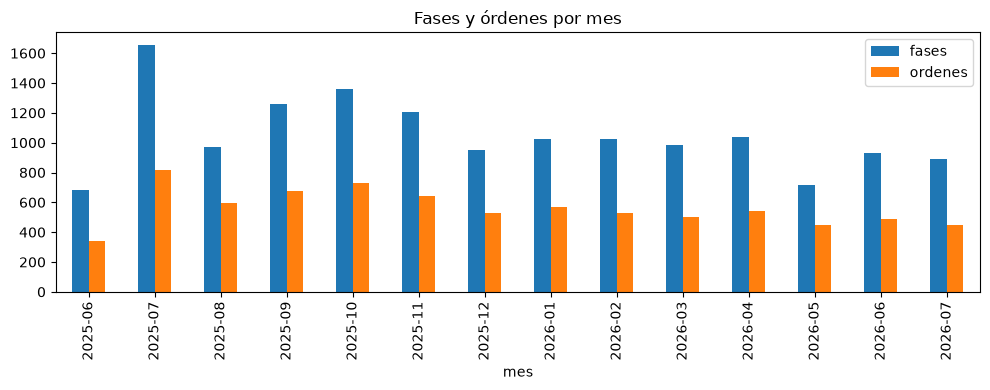

In [263]:
resumen_mes[["fases", "ordenes"]].plot(kind="bar", figsize=(10, 4), title="Fases y órdenes por mes")
plt.tight_layout()
plt.savefig(FIGURES / "10_fases_ordenes_por_mes.png", dpi=200, bbox_inches="tight")
plt.show()

> Es clave escoger validación cruzada, para evitar caer en meses atípicos para validación. Además de evitar data leakage, ya que no se entrenara el modelo con datos futuros a los que debe predecir en test.   

## 3. Diseño del reparto

En total se abarcan 14 meses y el reparto tiene que hacerse con meses enteros. Como orientación, un reparto
60 / 25 / 15 daría:
     
- Train: el 60 % de 14 es 8,4 meses. → redondeanod quedan 8 meses
- Validación: el 25 % de 14 es 3,5 meses. → redondeando quedan 3 meses
- Test: el 15 % de 14 es 2,1 meses. → redondeando quedan 3 meses
     
El reparto final es:

- **Test:** las órdenes iniciadas a partir del 1 de mayo de 2026 (mayo, junio y julio de 2026).
- **Desarrollo:** las órdenes iniciadas antes (junio de 2025 a abril de 2026, 11 meses). Dentro de desarrollo se valida con 3 folds temporales (febrero, marzo y abril de 2026).

## 4. Asignar cada orden a un bloque

Cada orden pertenece al mes en que se hizo su primera imputación, es decir, el mes de su primera fase.

In [264]:
CORTE_TEST = pd.Timestamp("2026-05-01")

df_split = df_features.copy()

# 1. Fecha de la primera fase de cada orden
primera_fase = df_split.groupby("smOrdenId")["fecha_fase"].min()

# 2. Añadir columna con la fecha de inicio de la orden
df_split["inicio_orden"] = df_split["smOrdenId"].map(primera_fase)

# 3. Mes de inicio de la orden (servirá para los folds de validación).
#    Se guarda como texto ('2025-06', ...) porque parquet no guarda bien el tipo Period.
df_split["mes_orden"] = df_split["inicio_orden"].dt.to_period("M").astype(str)

# 4. Bloque según el inicio de la orden
df_split["split"] = np.where(df_split["inicio_orden"] < CORTE_TEST, "desarrollo", "test")

print(df_split["split"].value_counts())
print(df_split["split"].value_counts(normalize=True).round(3))

split
desarrollo    12229
test           2460
Name: count, dtype: int64
split
desarrollo    0.833
test          0.167
Name: proportion, dtype: float64


## 5. Verificar la partición

Reviso aquellas OF que están en medio del corte, es decir, las que tienen fases antes del corte y fases después.

In [265]:
invaden = df_split[(df_split["split"] == "desarrollo") & (df_split["fecha_fase"] >= CORTE_TEST)]
print(f"Fases de desarrollo posteriores al corte: {len(invaden)} ({len(invaden) / len(df_split):.1%})")

Fases de desarrollo posteriores al corte: 78 (0.5%)


Decido conservar esas fases.La partición temporal se realiza a nivel de orden de
fabricación, según la fecha de inicio de cada OF. Las órdenes iniciadas antes del 1 de mayo de 2026 se asignan íntegramente al conjunto de desarrollo, aunque alguna de sus fases se ejecute con posterioridad (78 fases).

Reviso el reparto de los artículos y las familias de máquinas entre los dos bloques:

In [266]:
for col in ["Línea Producto", "Família Producto", "Familia Maquinas"]:
    print(pd.crosstab(df_split[col], df_split["split"], normalize="columns").round(3), "\n")

split           desarrollo   test
Línea Producto                   
B                    0.258  0.258
CBN                  0.002  0.003
CF                   0.011  0.017
CO                   0.028  0.032
E                    0.060  0.069
IC                   0.010  0.013
IT                   0.005  0.013
K                    0.000  0.008
M                    0.004  0.005
MAT                  0.000  0.002
P                    0.601  0.557
PBA                  0.011  0.007
PL                   0.006  0.007
PRJ                  0.000  0.000
REP                  0.001  0.000
SUP                  0.000  0.001
T                    0.004  0.005 

split             desarrollo   test
Família Producto                   
BAL                    0.037  0.039
BR                     0.167  0.168
BX                     0.054  0.053
CBN                    0.002  0.003
CFF                    0.011  0.018
COD                    0.017  0.021
COP                    0.005  0.003
COR                    0.006

Categorías que aparecen en test pero no en desarrollo:

In [267]:
for col in ["CodigoMaquina", "Familia Maquinas", "TipoFase", "Línea Producto", "Família Producto"]:
    nuevas = (set(df_split.loc[df_split["split"] == "test", col].dropna())
              - set(df_split.loc[df_split["split"] == "desarrollo", col].dropna()))
    print(f"{col}: {len(nuevas)} categorías solo en test → {sorted(nuevas)}")

CodigoMaquina: 2 categorías solo en test → ['CM18', 'CM19']
Familia Maquinas: 0 categorías solo en test → []
TipoFase: 0 categorías solo en test → []
Línea Producto: 0 categorías solo en test → []
Família Producto: 1 categorías solo en test → ['KCX']


La máquina CM19 no está en la partición de desarrollo: se incorporó a finales de mayo de 2026 y su primera fase
registrada es del 22 de junio de 2026.

Esto es destacable: ¿cómo predice el modelo en una máquina que nunca ha visto, apoyándose solo en su familia?

Dejo una marca en esa máquina. Esta marca no es una variable del modelo (nunca entra en el entrenamiento ni en la
predicción), sino una etiqueta de análisis: se usa después de predecir, para separar el error en grupos.

In [268]:
maquinas_desarrollo = set(df_split.loc[df_split["split"] == "desarrollo", "CodigoMaquina"])
df_split["maquina_no_vista"] = ~df_split["CodigoMaquina"].isin(maquinas_desarrollo)

n_no_vista = df_split["maquina_no_vista"].sum()
n_test = (df_split["split"] == "test").sum()

print("Fases en máquinas no vistas en desarrollo:")
print(df_split.groupby("split")["maquina_no_vista"].sum())
print("\nMáquinas no vistas en desarrollo:", df_split.loc[df_split["maquina_no_vista"], "CodigoMaquina"].unique())
print(f"\nPeso de esas fases: {n_no_vista / len(df_split):.1%} del total y {n_no_vista / n_test:.1%} del test")

Fases en máquinas no vistas en desarrollo:
split
desarrollo     0
test          40
Name: maquina_no_vista, dtype: int64

Máquinas no vistas en desarrollo: ['CM19' 'CM18']

Peso de esas fases: 0.3% del total y 1.6% del test


> El tratamiento de estas maquinas lo hara una vez tenga el split de datos definido.

## 6. Folds de validación

Se ha determinado ejecutar validación cruzada. Al trabajar con datos temporales no puede aplicarse un reparto
aleatorio como el k-fold habitual, ya que el fold que valida no puede estar temporalmente por delante de datos de
entrenamiento: los folds siempre validan con datos futuros respecto a su entrenamiento. En cada fold se entrena con
todos los meses de desarrollo anteriores al mes de validación (ventana creciente).

Para decidir cuántos folds usar, comparo distintas opciones de k (los k últimos meses de desarrollo validan):

In [269]:
desarrollo = df_split[df_split["split"] == "desarrollo"]
meses = sorted(desarrollo["mes_orden"].unique())          # los 11 meses de desarrollo, en orden
fases_mes = desarrollo["mes_orden"].value_counts()

filas = []
for k in range(2, 6):
    meses_val = meses[-k:]                                # los k últimos meses validan
    train_fold1 = desarrollo[desarrollo["mes_orden"] < meses_val[0]]
    filas.append({
        "k": k,
        "meses_validacion": ", ".join(meses_val),
        "meses_train_fold1": len(meses) - k,
        "fases_train_fold1": len(train_fold1),
        "%_datos_fold1": round(len(train_fold1) / len(df_split) * 100, 1),
        "fases_val_min": fases_mes[meses_val].min(),      # el mes de validación más flojo
    })

print(pd.DataFrame(filas).to_string(index=False))

 k                            meses_validacion  meses_train_fold1  fases_train_fold1  %_datos_fold1  fases_val_min
 2                            2026-03, 2026-04                  9              10198           69.4            996
 3                   2026-02, 2026-03, 2026-04                  8               9258           63.0            940
 4          2026-01, 2026-02, 2026-03, 2026-04                  7               8250           56.2            940
 5 2025-12, 2026-01, 2026-02, 2026-03, 2026-04                  6               7362           50.1            888


## 7. Aplicar corte de outliers en las colas
En el notebook `08_variable_objetivo` se detecta que la distribució de los datos, para el radio, existen colas en ambas direcciones las cuales acumulan datos erroneos.     
En ese momento se determina que es necesario aplicar un umbral de corte en ambas colas para reducir errores acumulados. Este umbral de corte debe calcularse en Train y aplicarse con esos valores sobre Validación y Test.  

### 7.1 Aplicar el umbral de corte

Calculo el umbral de corte:

In [270]:
MESES_VALIDACION = ["2026-02", "2026-03", "2026-04"]
train_k1 =  desarrollo[desarrollo["mes_orden"] < MESES_VALIDACION[0]] # train para k1

UMBRAL_BAJO, UMBRAL_ALTO = corte_log(train_k1)

Umbrales: 0.259 (bajo) y 8.558 (alto)


Aplicar el corte a todo el dataset:

In [271]:
df_split_pre_cut = df_split.copy()
alta = (df_split["ratio"] >= UMBRAL_ALTO).sum()
baja = (df_split["ratio"] <= UMBRAL_BAJO).sum()


dentro = (df_split["ratio"] > UMBRAL_BAJO) & (df_split["ratio"] < UMBRAL_ALTO)
df_split = df_split[dentro]

print("-"*60)
print(df_split["split"].value_counts())
print("-"*60)

print(f"Descartadas en la cola alta (>= {UMBRAL_ALTO}): {alta}")
print(f"Descartadas en la cola baja (<= {UMBRAL_BAJO}): {baja}")
print(f"Fases: {len(df_split_pre_cut)} → {len(df_split)}\n")

------------------------------------------------------------
split
desarrollo    11761
test           2385
Name: count, dtype: int64
------------------------------------------------------------
Descartadas en la cola alta (>= 8.558): 211
Descartadas en la cola baja (<= 0.259): 332
Fases: 14689 → 14146



### 7.2 Figuras del corte

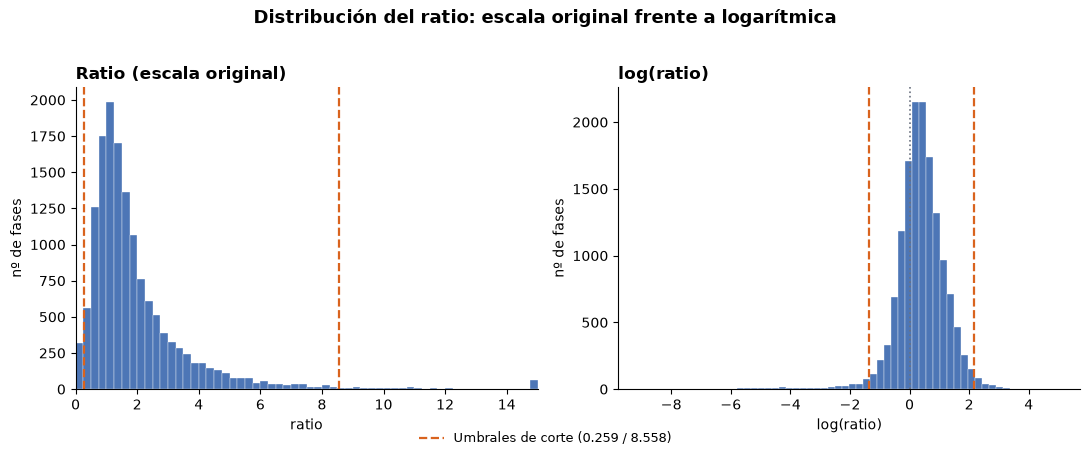

In [272]:
# GRAFICO CON RATIO VS LOG(RATIO)
log_ratio = np.log(df_split_pre_cut["ratio"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

ax = axes[0]
ax.hist(df_split_pre_cut["ratio"].clip(upper=15), bins=60, color=BLUE, alpha=0.85, edgecolor="white", linewidth=0.3)
for u in (UMBRAL_BAJO, UMBRAL_ALTO):
    ax.axvline(u, color=ORANGE, linewidth=1.6, linestyle="--")
ax.set_title("Ratio (escala original)", fontsize=12, fontweight="bold", loc="left")
ax.set_xlabel("ratio"); ax.set_ylabel("nº de fases"); ax.set_xlim(0, 15)

ax2 = axes[1]
ax2.hist(log_ratio, bins=60, color=BLUE, alpha=0.85, edgecolor="white", linewidth=0.3)
ax2.axvline(0, color=GRAY, linewidth=1.2, linestyle=":")
for u in (UMBRAL_BAJO, UMBRAL_ALTO):
    ax2.axvline(np.log(u), color=ORANGE, linewidth=1.6, linestyle="--")
ax2.set_title("log(ratio)", fontsize=12, fontweight="bold", loc="left")
ax2.set_xlabel("log(ratio)"); ax2.set_ylabel("nº de fases")

for a in axes:
    a.spines[["top", "right"]].set_visible(False)
fig.legend(handles=[Line2D([0], [0], color=ORANGE, lw=1.6, linestyle="--",
                          label=f"Umbrales de corte ({UMBRAL_BAJO} / {UMBRAL_ALTO})")],
            loc="lower center", frameon=False, bbox_to_anchor=(0.5, -0.02), fontsize=9)
fig.suptitle("Distribución del ratio: escala original frente a logarítmica", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES / "10_ratio_vs_log_ratio_umbrales.png", dpi=200, bbox_inches="tight")
plt.show()

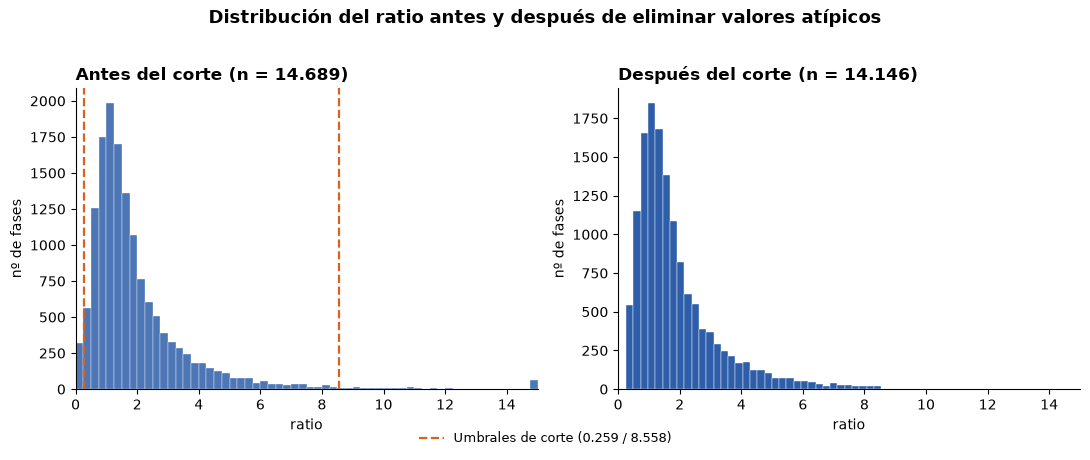

In [273]:
# GRAFICO CON RATIO ANTES Y DESPUES DEL CORTE
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

ax = axes[0]
ax.hist(df_split_pre_cut["ratio"].clip(upper=15), bins=60, color=BLUE, alpha=0.85, edgecolor="white", linewidth=0.3)
for u in (UMBRAL_BAJO, UMBRAL_ALTO):
    ax.axvline(u, color=ORANGE, linewidth=1.6, linestyle="--")
ax.set_title(f"Antes del corte (n = {len(df_split_pre_cut):,})".replace(",", "."), fontsize=12, fontweight="bold", loc="left")

ax2 = axes[1]
ax2.hist(df_split["ratio"], bins=35, color=BLUE, alpha=1, edgecolor="white", linewidth=0.3)
ax2.set_title(f"Después del corte (n = {len(df_split):,})".replace(",", "."), fontsize=12, fontweight="bold", loc="left")

for a in axes:
    a.set_xlabel("ratio"); a.set_ylabel("nº de fases"); a.set_xlim(0, 15)
    a.spines[["top", "right"]].set_visible(False)
fig.legend(handles=[Line2D([0], [0], color=ORANGE, lw=1.6, linestyle="--",
                           label=f"Umbrales de corte ({UMBRAL_BAJO} / {UMBRAL_ALTO})")],
           loc="lower center", frameon=False, bbox_to_anchor=(0.5, -0.02), fontsize=9)
fig.suptitle("Distribución del ratio antes y después de eliminar valores atípicos", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES / "08_corte_antes_despues.png", dpi=200, bbox_inches="tight")
plt.show()

Quedan 14.212 fases: 11.818 en desarrollo y 2.394 en test.

## 8. Tratar máquinas con poco volumen
En el notebook `09_seleccion_variables` se han identificado máquinas con pocas fases asociadas, estas se agruparán en un grupo `Otras` dentro de cada familia. **El número de fases de cada máquina se cuenta solo en el train del fold 1, igual que los umbrales del corte, para no usar información de validación ni de test.**

En este mismo notebook, en el apartado `5.`, se han identificado máquinas en test que no están en desarrollo, por lo tanto el modelo no podrá aprender esas máquinas en concreto.

Inspeccionado el reparto de fases en máquinas para train: 

In [274]:
conteo = pd.DataFrame({
    "train_k1": train_k1["CodigoMaquina"].value_counts(),
    "total": df_split["CodigoMaquina"].value_counts(),
}).fillna(0).astype(int)

print(conteo.sort_values("train_k1").head(12))

               train_k1  total
CodigoMaquina                 
CM19                  0     36
CM18                  0      1
CM11                  1      1
CM13                  1      1
MA02                  1      0
CM17                 17     15
CM04                 17     16
CM15                 45     75
TN07                 63    126
PH04                 76    120
CM07                 79    107
CM10                 85    145


Agrupar las máquinas con menos de 30 fases dentro de una categoria `Otras` para cada família:

In [275]:
MIN_FASES_MAQUINA = 30

# 1. Máquinas con pocas fases EN TRAIN (las que no aparecen en train no están en este conteo)
fases_train = train_k1["CodigoMaquina"].value_counts()
maquinas_raras = fases_train[fases_train < MIN_FASES_MAQUINA].index
print(f"Máquinas agrupadas en 'Otras' ({len(maquinas_raras)}): {list(maquinas_raras)}")

# 2. Se aplica a todo el dataset: desarrollo y test
mask = df_split["CodigoMaquina"].isin(maquinas_raras)
df_split.loc[mask, "CodigoMaquina"] = "Otras_" + df_split.loc[mask, "Familia Maquinas"]

# 3. Comprobaciones
print("\nFases agrupadas por categoría y bloque:")
print(pd.crosstab(df_split.loc[mask, "CodigoMaquina"], df_split.loc[mask, "split"]))

print(f"\nMáquinas (incluidas las categorías 'Otras'): {df_split['CodigoMaquina'].nunique()}")

print("\nMáquinas no vistas en desarrollo (conservan su nombre):")
print(df_split.loc[df_split["maquina_no_vista"], "CodigoMaquina"].value_counts())

Máquinas agrupadas en 'Otras' (5): ['CM04', 'CM17', 'CM13', 'CM11', 'MA02']

Fases agrupadas por categoría y bloque:
split          desarrollo
CodigoMaquina            
Otras_C5               15
Otras_CV-ALU           16
Otras_FLEX              2

Máquinas (incluidas las categorías 'Otras'): 26

Máquinas no vistas en desarrollo (conservan su nombre):
CodigoMaquina
CM19    36
CM18     1
Name: count, dtype: int64


> Las maquinas que existen en Test pero no en Desarrollo ya se han marcado en el punto `5` de este notebook. 

## 9. Guardado

Se guardan el dataset con la partición y los folds, para no tener que definirlos cada vez que se usen.

In [276]:
folds = pd.DataFrame({
    "fold": range(1, len(MESES_VALIDACION) + 1),
    "mes_validacion": MESES_VALIDACION,
})
print(folds)

df_split.to_parquet(MODELING / "df_split.parquet", index=False)
folds.to_csv(MODELING / "folds.csv", index=False)

# Comprobación: se relee y coincide
check = pd.read_parquet(MODELING / "df_split.parquet")
print(check.shape)
print(check["split"].value_counts())

   fold mes_validacion
0     1        2026-02
1     2        2026-03
2     3        2026-04
(14146, 15)
split
desarrollo    11761
test           2385
Name: count, dtype: int64
